In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA_PATH = Path(r"C:\Users\dparh\Desktop\ML\Assignments\Assignment-1\data")

sns.set_style("whitegrid")
sns.set_palette("viridis")

df = pd.read_csv(DATA_PATH / "jardin_data.csv")

df.head(5)

,Fecha,21085040,21050140,21080070,21085020,21080130,21080110,21080080,21085040_temp,21085020_temp,...,Caudal_lag4,Caudal_lag5,Caudal_lag6,Caudal,Month_sin,Month_cos,Season_Autumn,Season_Spring,Season_Summer,Season_Winter
0,1988-01-08,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,19.381280,22.600000,...,2.93,3.46,3.46,2.15,0.5,0.866025,False,False,False,True
1,1988-01-09,0.008215,0.095884,0.0,0.0,0.0,0.0,0.0,19.606246,24.051185,...,2.62,2.93,3.46,2.11,0.5,0.866025,False,False,False,True
2,1988-01-10,0.857096,1.055658,0.0,13.8,0.0,3.4,0.1,19.485019,23.929958,...,2.41,2.62,2.93,2.13,0.5,0.866025,False,False,False,True
3,1988-01-11,0.857685,0.880242,0.0,0.0,0.0,0.0,0.0,19.819736,24.300000,...,2.20,2.41,2.62,2.40,0.5,0.866025,False,False,False,True
4,1988-01-12,0.793631,1.722695,5.0,0.0,0.5,0.0,0.0,19.846713,24.500000,...,2.15,2.20,2.41,2.16,0.5,0.866025,False,False,False,True


In [46]:
df.describe()

,21085040,21050140,21080070,21085020,21080130,21080110,21080080,21085040_temp,21085020_temp,21085040_lag1,...,21085020_temp_lag4,Caudal_lag1,Caudal_lag2,Caudal_lag3,Caudal_lag4,Caudal_lag5,Caudal_lag6,Caudal,Month_sin,Month_cos
count,12077.000000,12077.000000,12077.000000,12077.000000,12077.000000,12077.000000,12077.000000,12077.000000,12077.000000,12077.000000,...,12077.000000,12077.000000,12077.000000,12077.000000,12077.000000,12077.000000,12077.000000,12077.000000,1.207700e+04,1.207700e+04
mean,5.436559,4.587451,5.089357,5.380075,5.333534,4.517747,4.098438,19.045739,23.494100,5.435937,...,23.493552,9.786816,9.801653,9.805256,9.814858,9.823798,9.838630,9.770294,5.452460e-03,-1.127195e-02
std,10.370126,11.296100,12.381282,11.151401,11.808026,9.730507,8.429222,1.146442,1.281842,10.367506,...,1.281481,15.446323,15.641681,15.664161,15.680331,15.701263,15.738766,14.960881,7.049746e-01,7.091804e-01
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,15.564578,19.500000,0.000000,...,19.500000,0.100000,0.100000,0.100000,0.100000,0.100000,0.100000,0.100000,-1.000000e+00,-1.000000e+00
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,18.249862,22.700000,0.000000,...,22.700000,2.120000,2.126563,2.126563,2.130000,2.130000,2.126563,2.126563,-5.000000e-01,-8.660254e-01
50%,0.900000,0.000000,0.000000,0.581644,0.000000,0.000000,0.000000,19.100000,23.557573,0.900000,...,23.557054,4.500000,4.500000,4.500000,4.500000,4.500000,4.500000,4.500000,1.224647e-16,-1.836970e-16
75%,5.601052,3.000000,2.000000,5.086233,4.500000,4.300000,4.000000,19.826776,24.342912,5.608239,...,24.341926,10.575688,10.570000,10.560563,10.560000,10.560563,10.575688,10.570000,5.000000e-01,5.000000e-01
max,101.475625,81.000000,122.576308,141.542058,156.395124,100.047353,58.000000,23.337283,27.782222,101.475625,...,27.782222,465.400000,465.400000,465.400000,465.400000,465.400000,465.400000,224.500000,1.000000e+00,1.000000e+00


In [47]:
numeric = df.select_dtypes('number')

numeric.columns

Index(['21085040', '21050140', '21080070', '21085020', '21080130', '21080110',
       '21080080', '21085040_temp', '21085020_temp', '21085040_lag1',
       '21085040_lag2', '21085040_lag3', '21085040_lag4', '21085040_lag5',
       '21085040_lag6', '21085040_lag7', '21050140_lag1', '21050140_lag2',
       '21050140_lag3', '21050140_lag4', '21050140_lag5', '21050140_lag6',
       '21050140_lag7', '21080070_lag1', '21080070_lag2', '21080070_lag3',
       '21080070_lag4', '21080070_lag5', '21080070_lag6', '21080070_lag7',
       '21085020_lag1', '21085020_lag2', '21085020_lag3', '21085020_lag4',
       '21085020_lag5', '21085020_lag6', '21085020_lag7', '21080130_lag1',
       '21080130_lag2', '21080130_lag3', '21080130_lag4', '21080130_lag5',
       '21080130_lag6', '21080130_lag7', '21080110_lag1', '21080110_lag2',
       '21080110_lag3', '21080110_lag4', '21080110_lag5', '21080110_lag6',
       '21080110_lag7', '21080080_lag1', '21080080_lag2', '21080080_lag3',
       '21080080_lag4', '2

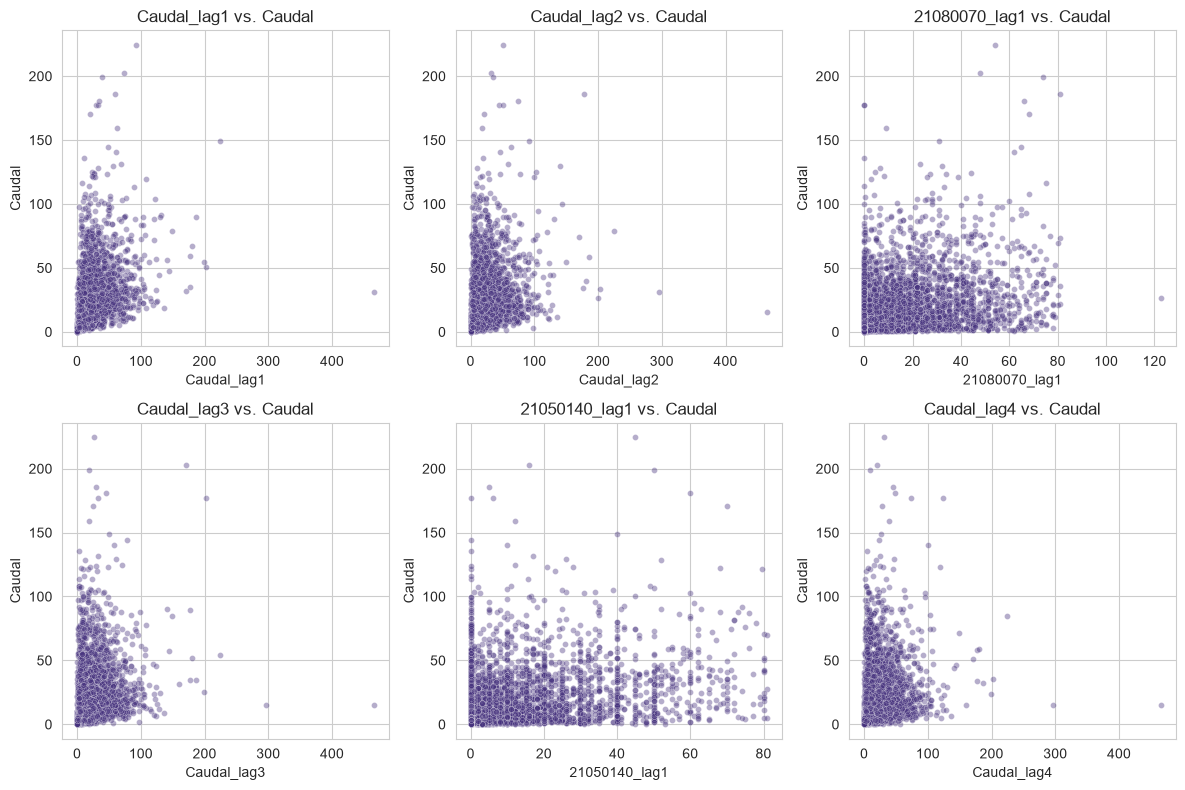

In [48]:
target = "Caudel" if "Caudel" in numeric.columns else "Caudal"

features = (
    numeric.corr()[target]
    .drop(target)
    .abs()
    .nlargest(6)
    .index
)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for feature, ax in zip(features, axes.flat):
    sns.scatterplot(data=numeric, x=feature, y=target, alpha=0.4, s=18, ax=ax)
    ax.set_title(f"{feature} vs. {target}")

plt.tight_layout()
plt.show()

In [49]:
corr_mtx = numeric.corr()

corr_mtx

,21085040,21050140,21080070,21085020,21080130,21080110,21080080,21085040_temp,21085020_temp,21085040_lag1,...,21085020_temp_lag4,Caudal_lag1,Caudal_lag2,Caudal_lag3,Caudal_lag4,Caudal_lag5,Caudal_lag6,Caudal,Month_sin,Month_cos
21085040,1.000000,0.332969,0.380475,0.563863,0.486494,0.470374,0.333027,-0.173096,-0.142067,0.223241,...,-0.033905,0.181351,0.146214,0.123811,0.101281,0.089074,0.085305,0.271805,0.123522,0.118097
21050140,0.332969,1.000000,0.451162,0.325214,0.390566,0.334088,0.245831,-0.109567,-0.084197,0.137758,...,-0.021993,0.136277,0.125420,0.096113,0.093641,0.075528,0.083008,0.206118,0.072531,0.163505
21080070,0.380475,0.451162,1.000000,0.388888,0.416662,0.359591,0.276841,-0.115947,-0.094462,0.146946,...,-0.010016,0.165559,0.141028,0.117188,0.109617,0.099159,0.097630,0.259979,0.087461,0.181020
21085020,0.563863,0.325214,0.388888,1.000000,0.657407,0.373610,0.264124,-0.172598,-0.134851,0.210851,...,-0.021411,0.175761,0.140801,0.120330,0.105243,0.089330,0.076996,0.267395,0.091531,0.145936
21080130,0.486494,0.390566,0.416662,0.657407,1.000000,0.344180,0.229256,-0.170304,-0.125460,0.200721,...,-0.015161,0.168051,0.130619,0.126407,0.103465,0.085458,0.088309,0.253168,0.080203,0.172191
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Caudal_lag5,0.089074,0.075528,0.099159,0.089330,0.085458,0.073488,0.059549,-0.127544,-0.068521,0.099978,...,-0.134935,0.405726,0.447164,0.510803,0.623183,1.000000,0.624554,0.381488,0.240448,0.163876
Caudal_lag6,0.085305,0.083008,0.097630,0.076996,0.088309,0.076564,0.054399,-0.121556,-0.066028,0.088036,...,-0.103099,0.370188,0.401293,0.446843,0.511771,0.624554,1.000000,0.376792,0.242875,0.159649
Caudal,0.271805,0.206118,0.259979,0.267395,0.253168,0.232462,0.186905,-0.244354,-0.187208,0.393412,...,-0.095367,0.606808,0.511759,0.461047,0.419852,0.381488,0.376792,1.000000,0.239743,0.186510
Month_sin,0.123522,0.072531,0.087461,0.091531,0.080203,0.118475,0.087171,-0.066524,-0.040390,0.125252,...,-0.031822,0.234950,0.234480,0.235536,0.238032,0.240448,0.242875,0.239743,1.000000,-0.004037


In [50]:
season_cols = df.filter(regex=r"^Season_").columns
df[season_cols] = df[season_cols].astype(int)

Time to implement some models

In [51]:
# start with a simple linear regression
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV, ElasticNet, ElasticNetCV
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, root_mean_squared_error

X = df.drop(columns=['Fecha', 'Caudal'], inplace=False)
y = df['Caudal']

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, test_size=0.2, random_state=2026)

In [52]:
X

,21085040,21050140,21080070,21085020,21080130,21080110,21080080,21085040_temp,21085020_temp,21085040_lag1,...,Caudal_lag3,Caudal_lag4,Caudal_lag5,Caudal_lag6,Month_sin,Month_cos,Season_Autumn,Season_Spring,Season_Summer,Season_Winter
0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,19.381280,22.600000,0.000000,...,2.620000,2.930000,3.460000,3.460000,0.500000,0.866025,0,0,0,1
1,0.008215,0.095884,0.000000,0.000000,0.000000,0.0,0.0,19.606246,24.051185,0.000000,...,2.410000,2.620000,2.930000,3.460000,0.500000,0.866025,0,0,0,1
2,0.857096,1.055658,0.000000,13.800000,0.000000,3.4,0.1,19.485019,23.929958,0.008215,...,2.200000,2.410000,2.620000,2.930000,0.500000,0.866025,0,0,0,1
3,0.857685,0.880242,0.000000,0.000000,0.000000,0.0,0.0,19.819736,24.300000,0.857096,...,2.150000,2.200000,2.410000,2.620000,0.500000,0.866025,0,0,0,1
4,0.793631,1.722695,5.000000,0.000000,0.500000,0.0,0.0,19.846713,24.500000,0.857685,...,2.110000,2.150000,2.200000,2.410000,0.500000,0.866025,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12072,1.350728,8.000000,1.958161,1.032818,0.753902,31.0,1.4,19.990249,24.435188,3.401444,...,10.258813,16.713625,3.673875,5.349375,0.866025,-0.500000,0,1,0,0
12073,6.565247,0.000000,32.000000,6.791080,6.623887,34.0,0.0,20.058730,24.503669,1.350728,...,3.577063,10.258813,16.713625,3.673875,0.866025,-0.500000,0,1,0,0
12074,14.577824,19.000000,19.000000,15.639165,15.643646,65.0,41.3,19.736343,24.181281,6.565247,...,2.644188,3.577063,10.258813,16.713625,0.866025,-0.500000,0,1,0,0
12075,61.106786,0.000000,22.000000,67.019921,68.021308,8.0,8.6,19.851363,24.296302,14.577824,...,3.698562,2.644188,3.577063,10.258813,0.866025,-0.500000,0,1,0,0


In [53]:
y

0         2.150000
1         2.110000
2         2.130000
3         2.400000
4         2.160000
           ...    
12072     3.698562
12073    21.003750
12074    20.354125
12075    25.858000
12076    34.807833
Name: Caudal, Length: 12077, dtype: float64

Simple Linear Regression

In [54]:
model_linear = LinearRegression().fit(X_train, y_train)

predictions_linear = model_linear.predict(X_test)

mse = mean_squared_error(y_test, predictions_linear)
rmse = np.sqrt(mse)

print("##### Linear regression performance #####")
print(f"R² score: {r2_score(y_test, predictions_linear):.4f}")
print(f"MSE:      {mse:.4f}")
print(f"RMSE:     {rmse:.4f}")
print(f"Intercept: {model_linear.intercept_:.4f}")

coefficients = pd.Series(
    model_linear.coef_,
    index=X_train.columns,
    name="coefficient"
).sort_values(key=abs, ascending=False)

display(coefficients)

##### Linear regression performance #####
R² score: 0.5980
MSE:      89.2368
RMSE:     9.4465
Intercept: 6.2609


Season_Autumn        -0.872537
21085020_temp_lag1    0.611045
Season_Winter         0.486557
Season_Spring         0.428546
21085040_temp_lag5   -0.321823
                        ...   
21080070_lag2         0.002998
21050140_lag3        -0.002589
21080070_lag6         0.002117
21080130_lag3        -0.000593
21080080_lag2         0.000517
Name: coefficient, Length: 81, dtype: float64

Ridge regression

In [55]:
# ! Ridge requires scaling for proper realisation
from sklearn.preprocessing import StandardScaler

X = df.drop(columns=['Fecha', 'Caudal'], inplace=False)
y = df['Caudal']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2026)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

model_ridge = Ridge(alpha=1.0)
model_ridge.fit(X_train_scaled, y_train)

predictions_ridge = model_ridge.predict(X_test_scaled)

# Performance measure
print(f"Coefficients (Ridge): {model_ridge.coef_}")
print("########################")
print(f"Intercept (Ridge): {model_ridge.intercept_}")
print(f"R squared score (Ridge): {model_ridge.score(X_test_scaled, y_test):.4f}")
print("########################")

Coefficients (Ridge): [ 0.45356374 -0.20855268  0.79902952  0.16599554 -0.04635026  0.08439584
  0.34587305  0.03566951 -0.15678344  0.47876249  0.21571859 -0.16406301
  0.04338124  0.05593535  0.09055216  0.17024195  2.19497155  0.21156433
 -0.02962337 -0.25987082 -0.45696615 -0.09640507 -0.15803396  2.47138191
  0.03738417  0.22277156 -0.06067311  0.13923255  0.02599651  0.08370088
  0.39816312 -0.16769756 -0.13789772 -0.29580198 -0.22812566 -0.31071887
 -0.41518125  0.84705503 -0.23104233 -0.00699411  0.46506229  0.17123541
  0.19763033  0.05409587  1.70283823  0.19344446 -0.05163733 -0.18495358
  0.10782833 -0.26539591 -0.25461931  0.59857824  0.0044271   0.04037293
  0.11113291  0.09100311  0.06651769 -0.09257075  0.11849813 -0.21996674
 -0.10953547 -0.02102985 -0.36793052 -0.03174001 -0.31460013  0.78650249
 -0.1989729   0.09983479 -0.06830107  3.7730898   1.75315572  1.68847642
  0.90292917  0.21692898  1.46132047 -0.08534253 -0.20673486 -0.37637123
  0.18610989 -0.01991841  0.2

In [56]:
# now tune the Ridge model with CV
param_grid = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
model_ridge = Ridge(fit_intercept=True, copy_X=True, positive=False)

configs = model_ridge.get_params()
alphas_test = np.logspace(-4,4,100)

ridge_cv = RidgeCV(
    alphas=param_grid,
    cv=None,
    fit_intercept=True
)

ridge_cv.fit(X_train_scaled, y_train)
print(f"Optimal lambda fot the Ridge model: {ridge_cv.alpha_}")

Optimal lambda fot the Ridge model: 100.0


In [57]:
model_ridge_optimal = Ridge(alpha=100, max_iter=1000)
model_ridge_optimal.fit(X_train_scaled, y_train)
predictions_ridge_optimal = model_ridge_optimal.predict(X_test_scaled)

# Performance measure
print(f"Coefficients (Ridge optimal): {model_ridge_optimal.coef_}")
print("########################")
print(f"Intercept (Ridge optimal): {model_ridge_optimal.intercept_}")
print(f"R squared score (Ridge optimal): {model_ridge_optimal.score(X_test_scaled, y_test):.4f}")
print(f"RMSE for (Ridge optimal): {mean_squared_error(y_test, predictions_ridge_optimal):.4f}")
print("########################")

Coefficients (Ridge optimal): [ 0.44993644 -0.20053553  0.79047115  0.168609   -0.04063692  0.088091
  0.34534682  0.02622723 -0.15222775  0.48703856  0.2138845  -0.15884687
  0.04233544  0.05482712  0.08722536  0.16251885  2.17848856  0.21888463
 -0.02674312 -0.2529723  -0.44860914 -0.09911913 -0.15447693  2.45156839
  0.05098612  0.22436636 -0.05492649  0.13801799  0.02423987  0.0870212
  0.40626274 -0.16341041 -0.13685578 -0.2854344  -0.22334257 -0.30259312
 -0.40332716  0.84423816 -0.22145964 -0.0068742   0.45325843  0.16692744
  0.18972856  0.05081276  1.68850868  0.19763751 -0.04985871 -0.17869358
  0.10621169 -0.26310705 -0.24817258  0.60001605  0.00712868  0.04065459
  0.1096269   0.09052457  0.06576276 -0.09055283  0.12279795 -0.21750325
 -0.10886908 -0.02687777 -0.36148919 -0.03786288 -0.31351361  0.76888536
 -0.18828606  0.09693154 -0.06358709  3.71051188  1.75516561  1.67915205
  0.90677664  0.24111969  1.44104704 -0.06304416 -0.19129104 -0.37103916
  0.18258403 -0.0111105 

Lasso model

In [58]:
model_lasso = Lasso(max_iter=1000)

X = df.drop(columns=['Fecha', 'Caudal'], inplace=False)
y = df['Caudal']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2026)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

model_lasso.fit(X_train_scaled, y_train)
predictions_lasso = model_lasso.predict(X_test_scaled)

print(f"Coefficients (Lasso): {model_lasso.coef_}")
print("########################")
print(f"Intercept (Lasso): {model_lasso.intercept_}")
print(f"R squared score (Lasso): {model_lasso.score(X_test_scaled, y_test):.4f}")
print(f"RMSE for (Lasso): {mean_squared_error(y_test, predictions_lasso):.4f}")
print("########################")

Coefficients (Lasso): [ 0.20177621  0.          0.29497921  0.          0.          0.
  0.         -0.         -0.          0.35268891  0.          0.
  0.          0.          0.          0.          1.85941978  0.
  0.          0.          0.          0.          0.          2.33160581
  0.          0.          0.          0.          0.          0.
  0.26364714  0.          0.          0.          0.          0.
  0.          0.63565538  0.          0.          0.          0.
  0.          0.          1.41932633  0.          0.          0.
  0.          0.          0.          0.08763412  0.          0.
  0.          0.          0.          0.         -0.         -0.
 -0.         -0.         -0.         -0.         -0.          0.
 -0.         -0.         -0.          3.89158373  1.61480822  1.38787925
  0.65172962  0.          0.95944091  0.          0.         -0.
  0.         -0.          0.        ]
########################
Intercept (Lasso): 9.782229773573926
R squared score (

In [59]:
# tune the Lasso model with LassCV
model_lasso_cv = LassoCV(cv=5, random_state=2026)

model_lasso_cv.fit(X_train_scaled, y_train)
predictions_lasso_cv = model_lasso_cv.predict(X_test_scaled)

# Performance measure
print(f"Optimal alpha (LassoCV): {model_lasso_cv.alpha_}")
print(f"Coefficients (LassoCV): {model_lasso_cv.coef_}")
print(f"R squared score (LassoCV): {model_lasso_cv.score(X_test_scaled, y_test):.4f}")
print(f"RMSE for (LassoCV): {mean_squared_error(y_test, predictions_lasso_cv):.4f}")

Optimal alpha (LassoCV): 0.15662078537035426
Coefficients (LassoCV): [ 4.26576154e-01 -0.00000000e+00  6.66375244e-01  9.63701690e-02
  0.00000000e+00  0.00000000e+00  2.48038502e-01 -0.00000000e+00
 -0.00000000e+00  4.63358733e-01  0.00000000e+00 -0.00000000e+00
 -0.00000000e+00  0.00000000e+00 -0.00000000e+00  0.00000000e+00
  2.13317025e+00  3.62286423e-02  0.00000000e+00 -8.31167671e-03
 -1.51040557e-01 -0.00000000e+00 -0.00000000e+00  2.46971726e+00
  0.00000000e+00  0.00000000e+00 -0.00000000e+00  0.00000000e+00
 -0.00000000e+00  0.00000000e+00  3.74366167e-01 -0.00000000e+00
 -0.00000000e+00 -0.00000000e+00 -0.00000000e+00 -0.00000000e+00
 -1.39227606e-01  8.07356627e-01 -0.00000000e+00 -0.00000000e+00
  5.00289336e-02  0.00000000e+00  0.00000000e+00 -0.00000000e+00
  1.64074019e+00  2.65305185e-02 -0.00000000e+00 -0.00000000e+00
  0.00000000e+00 -3.69643754e-02 -1.70855725e-02  4.97943896e-01
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00 -0.0

Elastic Net model

In [60]:
# Elastic Net with cross-validated hyperparameter tuning
X = df.drop(columns=["Fecha", "Caudal"])
y = df["Caudal"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=2026
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model_elastic_net_cv = ElasticNetCV(
    l1_ratio=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 1.0],
    alphas=np.logspace(-4, 2, 100),
    cv=5,
    max_iter=20000,
    random_state=2026,
    n_jobs=-1
)

model_elastic_net_cv.fit(X_train_scaled, y_train)
predictions_elastic_net = model_elastic_net_cv.predict(X_test_scaled)

print(f"Best alpha:   {model_elastic_net_cv.alpha_:.6g}")
print(f"Best l1_ratio: {model_elastic_net_cv.l1_ratio_:.2f}")
print(f"R²:           {r2_score(y_test, predictions_elastic_net):.4f}")
print(f"RMSE:         {np.sqrt(mean_squared_error(y_test, predictions_elastic_net)):.4f}")

elastic_coefficients = pd.Series(
    model_elastic_net_cv.coef_,
    index=X_train.columns,
    name="coefficient"
).sort_values(key=abs, ascending=False)

display(elastic_coefficients)

Best alpha:   0.187382
Best l1_ratio: 0.75
R²:           0.6029
RMSE:         9.3892


Caudal_lag1           3.582959
21080070_lag1         2.381585
21050140_lag1         2.073239
Caudal_lag2           1.732572
21080110_lag1         1.591626
                        ...   
21085020_temp_lag2   -0.000000
21085020_temp_lag3   -0.000000
Month_cos            -0.000000
Season_Summer        -0.000000
Season_Winter         0.000000
Name: coefficient, Length: 81, dtype: float64

In [61]:
def choose_best_model(models, X_test_scaled, y_test):
    best_model = None
    best_score = -np.inf
    
    for model in models:
        score = model.score(X_test_scaled, y_test)
        if score > best_score:
            best_score = score
            best_model = model
    print(f"Found best model: {best_model.__class__.__name__} with R² score: {best_score:.4f}")
    return best_model

print(choose_best_model([model_linear, model_ridge_optimal, model_lasso_cv, model_elastic_net_cv], X_test_scaled, y_test))

Found best model: LassoCV with R² score: 0.6050
LassoCV(cv=5, random_state=2026)


c:\Users\dparh\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


Lasso Wins

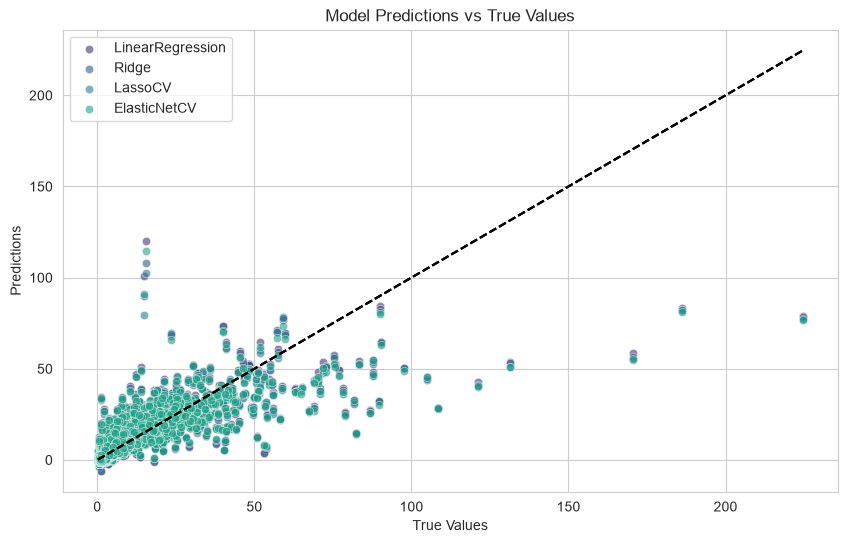

In [62]:
# Plot the fours models
fig, ax = plt.subplots(figsize=(10, 6))
for model, predictions in zip([model_linear, model_ridge_optimal, model_lasso_cv, model_elastic_net_cv], [predictions_linear, predictions_ridge_optimal, predictions_lasso_cv, predictions_elastic_net]):
    sns.scatterplot(x=y_test, y=predictions, label=model.__class__.__name__, alpha=0.6, ax=ax)
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='black', linestyle='--', alpha=0.8)
    ax.set_xlabel('True Values')
    ax.set_ylabel('Predictions')
    ax.legend()

plt.title('Model Predictions vs True Values')
plt.show()

In [64]:
def nash_sutcliffe_efficiency(y_true, y_pred):
    numerator = np.sum((y_true - y_pred) ** 2)
    denominator = np.sum((y_true - np.mean(y_true)) ** 2)
    
    return 1 - (numerator / denominator)

print(f"Model Linear Regression NSE: {nash_sutcliffe_efficiency(y_test, predictions_linear):.4f}")
print(f"Model Ridge Regression NSE: {nash_sutcliffe_efficiency(y_test, predictions_ridge_optimal):.4f}")
print(f"Model Lasso Regression NSE: {nash_sutcliffe_efficiency(y_test, predictions_lasso_cv):.4f}")
print(f"Model Elastic Net Regression NSE: {nash_sutcliffe_efficiency(y_test, predictions_elastic_net):.4f}")

Model Linear Regression NSE: 0.5980
Model Ridge Regression NSE: 0.6070
Model Lasso Regression NSE: 0.6124
Model Elastic Net Regression NSE: 0.6029


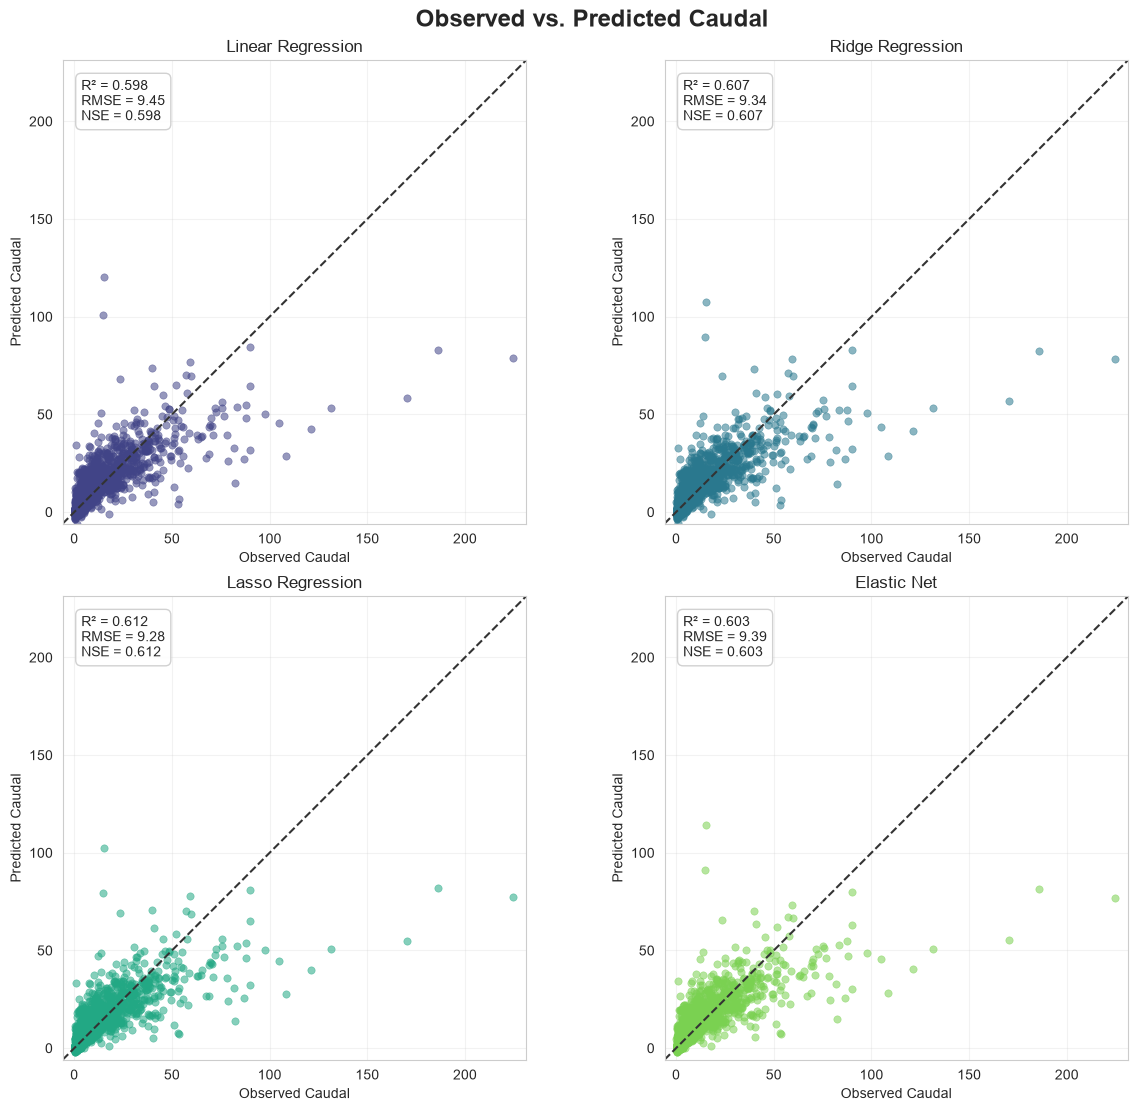

In [66]:
model_results = [
    ("Linear Regression", predictions_linear),
    ("Ridge Regression", predictions_ridge_optimal),
    ("Lasso Regression", predictions_lasso_cv),
    ("Elastic Net", predictions_elastic_net),
]

colors = sns.color_palette("viridis", len(model_results))
all_values = np.concatenate([y_test.to_numpy(), *[pred for _, pred in model_results]])
lower = min(0, all_values.min())
upper = all_values.max() * 1.03

fig, axes = plt.subplots(2, 2, figsize=(12, 11), constrained_layout=True)

for ax, (name, pred), color in zip(axes.flat, model_results, colors):
    sns.scatterplot(
        x=y_test, y=pred, ax=ax, color=color,
        alpha=0.55, s=28, edgecolor=None
    )
    ax.plot([lower, upper], [lower, upper], "--", color="#333333", lw=1.5)

    r2 = r2_score(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    nse = nash_sutcliffe_efficiency(y_test, pred)

    ax.set(
        title=name,
        xlabel="Observed Caudal",
        ylabel="Predicted Caudal",
        xlim=(lower, upper),
        ylim=(lower, upper),
    )
    ax.set_aspect("equal", adjustable="box")
    ax.grid(True, alpha=0.25)
    ax.text(
        0.04, 0.96,
        f"R² = {r2:.3f}\nRMSE = {rmse:.2f}\nNSE = {nse:.3f}",
        transform=ax.transAxes,
        va="top",
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.9, edgecolor="0.8"),
    )

fig.suptitle("Observed vs. Predicted Caudal", fontsize=17, fontweight="bold")
plt.show()